--- Regresión Lineal ---
MAE:  19576.04
RMSE: 188628.41
R2:   0.0098

--- Random Forest ---
MAE:  14534.22
RMSE: 185618.35
R2:   0.0411



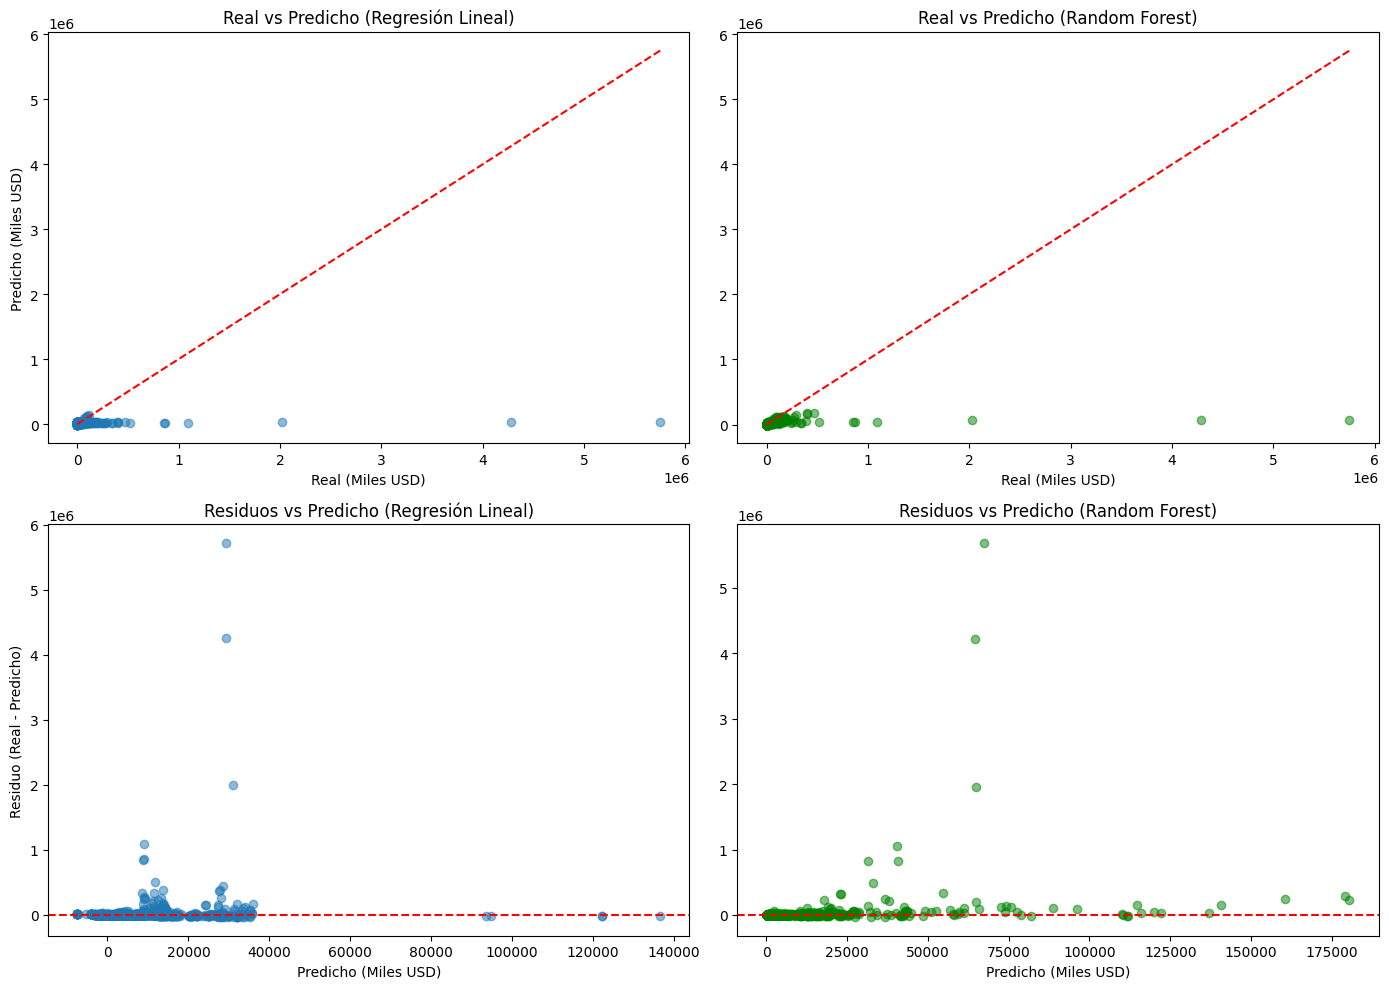

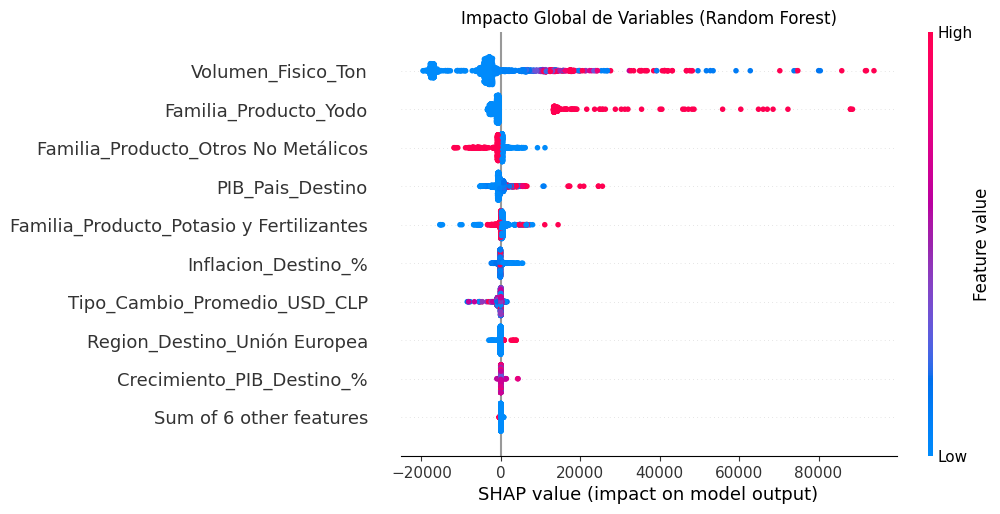

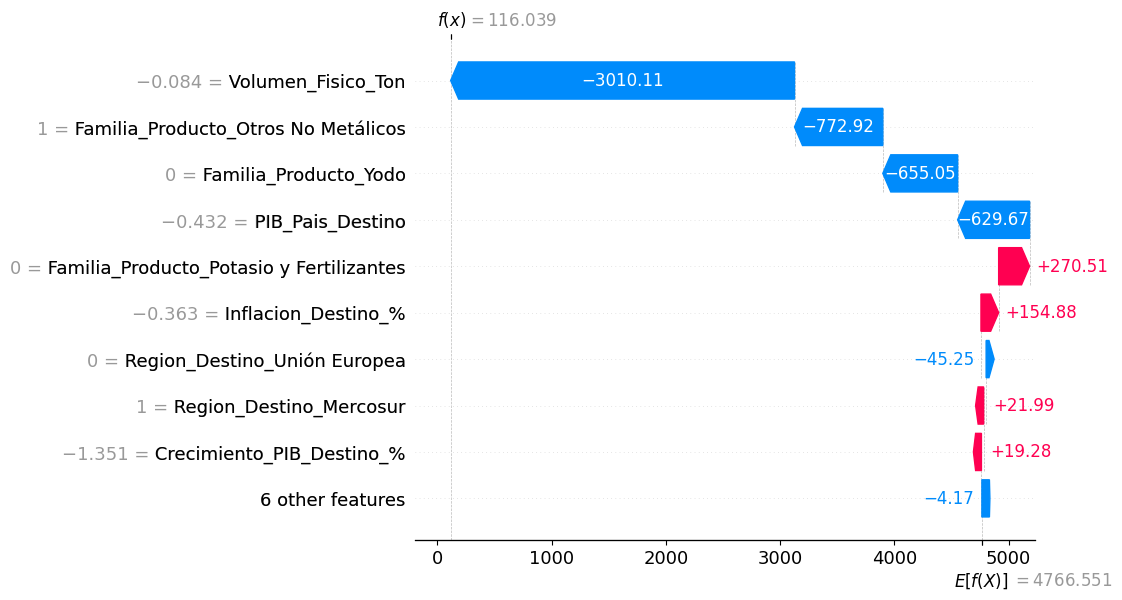

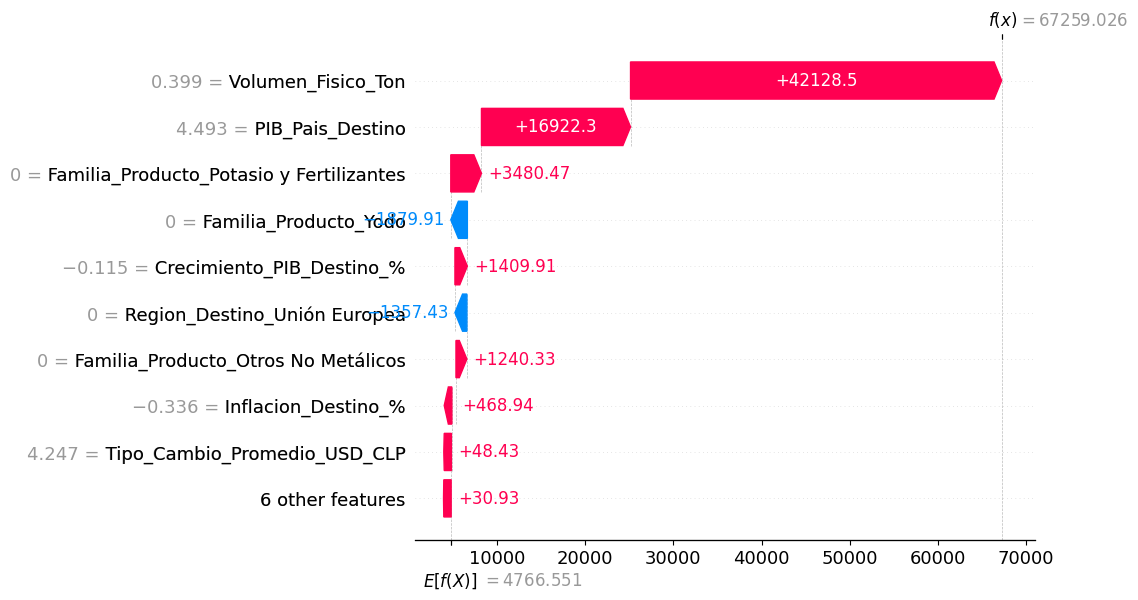

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. PREPARACIÓN (Filtrar activos y separar Test temporal)
df = pd.read_csv('Mineria_Final.csv', sep=';')
df_act = df[df['Valor_FOB_Miles_USD'] > 0].copy()

train_mask = df_act['Año'] <= 2019
test_mask = df_act['Año'] >= 2020

cat_cols = ['Familia_Producto', 'Region_Destino']
num_cols = ['Volumen_Fisico_Ton', 'Inflacion_Destino_%', 'PIB_Pais_Destino',
            'Crecimiento_PIB_Destino_%', 'Tipo_Cambio_Promedio_USD_CLP']

X_train, y_train = df_act[train_mask][cat_cols + num_cols], df_act[train_mask]['Valor_FOB_Miles_USD']
X_test, y_test = df_act[test_mask][cat_cols + num_cols], df_act[test_mask]['Valor_FOB_Miles_USD']

# 2. PIPELINES Y ENTRENAMIENTO
preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('scal', StandardScaler())]), num_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), cat_cols)
    ])

lin_reg = Pipeline([('prep', preprocessor), ('reg', LinearRegression())])
rf_reg = Pipeline([('prep', preprocessor), ('reg', RandomForestRegressor(n_estimators=100, max_depth=6, random_state=42))])

lin_reg.fit(X_train, y_train)
rf_reg.fit(X_train, y_train)

pred_lin = lin_reg.predict(X_test)
pred_rf = rf_reg.predict(X_test)

# 3. TABLA DE MÉTRICAS (Slide 4)
def metrics(y_true, y_pred, name):
    print(f"--- {name} ---")
    print(f"MAE:  {mean_absolute_error(y_true, y_pred):.2f}")
    print(f"RMSE: {np.sqrt(mean_squared_error(y_true, y_pred)):.2f}")
    print(f"R2:   {r2_score(y_true, y_pred):.4f}\n")

metrics(y_test, pred_lin, "Regresión Lineal")
metrics(y_test, pred_rf, "Random Forest")

# 4. GRÁFICOS REAL VS PRED Y RESIDUOS (Slide 5)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Real vs Pred (Lineal)
axes[0,0].scatter(y_test, pred_lin, alpha=0.5)
axes[0,0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
axes[0,0].set_title('Real vs Predicho (Regresión Lineal)')
axes[0,0].set_xlabel('Real (Miles USD)')
axes[0,0].set_ylabel('Predicho (Miles USD)')

# Real vs Pred (RF)
axes[0,1].scatter(y_test, pred_rf, alpha=0.5, color='green')
axes[0,1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
axes[0,1].set_title('Real vs Predicho (Random Forest)')
axes[0,1].set_xlabel('Real (Miles USD)')

# Residuos (Lineal)
res_lin = y_test - pred_lin
axes[1,0].scatter(pred_lin, res_lin, alpha=0.5)
axes[1,0].axhline(0, color='r', linestyle='--')
axes[1,0].set_title('Residuos vs Predicho (Regresión Lineal)')
axes[1,0].set_xlabel('Predicho (Miles USD)')
axes[1,0].set_ylabel('Residuo (Real - Predicho)')

# Residuos (RF)
res_rf = y_test - pred_rf
axes[1,1].scatter(pred_rf, res_rf, alpha=0.5, color='green')
axes[1,1].axhline(0, color='r', linestyle='--')
axes[1,1].set_title('Residuos vs Predicho (Random Forest)')
axes[1,1].set_xlabel('Predicho (Miles USD)')
plt.tight_layout()
plt.show()

# 5. EXPLICABILIDAD SHAP (Slides 6, 7 y 8)
X_test_prep = preprocessor.transform(X_test)
features = num_cols + list(preprocessor.named_transformers_['cat'].get_feature_names_out(cat_cols))

explainer = shap.TreeExplainer(rf_reg.named_steps['reg'])
shap_values = explainer(X_test_prep)
shap_values.feature_names = features

# Slide 6: Global
shap.plots.beeswarm(shap_values, show=False)
plt.title("Impacto Global de Variables (Random Forest)")
plt.show()

# Slide 7: Acierto / Error Bajo (Busca un caso con residuo cercano a 0)
idx_low_error = np.argmin(np.abs(res_rf))
shap.plots.waterfall(shap_values[idx_low_error])

# Slide 8: Error Alto / Subestimación severa (Busca el caso con mayor residuo positivo)
idx_high_error = np.argmax(res_rf)
shap.plots.waterfall(shap_values[idx_high_error])